In [3]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import torch
from ultralytics import YOLO

# Проверяем GPU
device = "cuda:0" if torch.cuda.is_available() else "cpu"
print(f"Вычислительное устройство: {device}")
if device.startswith("cuda"):
    print(f"Видеокарта: {torch.cuda.get_device_name(0)}")

Вычислительное устройство: cuda:0
Видеокарта: NVIDIA GeForce RTX 4060 Ti


In [10]:
from pathlib import Path
import numpy as np
import torch
from ultralytics import YOLO

# 1. Загружаем официальный Nano-классификатор YOLO26
embedder = YOLO("yolo26n-cls.pt")
embedder.to(device)


def extract_embeddings(
    image_paths: list[Path], batch_size: int = 16
) -> np.ndarray:
    """Извлекает и L2-нормализует эмбеддинги через yolo26n-cls."""
    embeddings_list = []

    for i in range(0, len(image_paths), batch_size):
        batch = [str(p) for p in image_paths[i : i + batch_size]]

        with torch.no_grad():
            feats = embedder.embed(source=batch, verbose=False)

            if isinstance(feats, torch.Tensor):
                feats = feats.cpu().numpy()
            elif isinstance(feats, list):
                feats = np.array([
                    f.cpu().numpy() if isinstance(f, torch.Tensor) else f
                    for f in feats
                ])

            if feats.ndim == 1:
                feats = feats.reshape(1, -1)

            # L2-нормализация векторов
            norms = np.linalg.norm(feats, axis=1, keepdims=True)
            norms[norms == 0] = 1e-10
            feats_norm = feats / norms

            embeddings_list.append(feats_norm)

    return np.vstack(embeddings_list)


print("Экстрактор yolo26n-cls готов к работе.")

Экстрактор yolo26n-cls готов к работе.


In [7]:
from pathlib import Path
import pandas as pd

# Базовые директории
DATASET_ROOT = Path(r"D:\Tabmed\ePillID_data")
CSV_PATH = (
    DATASET_ROOT
    / "folds"
    / "pilltypeid_nih_sidelbls0.01_metric_5folds"
    / "base"
    / "pilltypeid_nih_sidelbls0.01_metric_5folds_all.csv"
)
IMAGES_BASE = DATASET_ROOT / "classification_data"

# Читаем сводную таблицу
df = pd.read_csv(CSV_PATH)

# Формируем абсолютный путь к каждому файлу на диске
df["full_path"] = df["image_path"].apply(
    lambda rel_path: IMAGES_BASE / Path(rel_path)
)

print(f"Всего записей в датасете: {len(df)}")
print(f"Уникальных препаратов: {df['pilltype_id'].nunique()}")

# Для первого теста выбираем 8 наиболее представленных классов
top_classes = df["pilltype_id"].value_counts().head(8).index.tolist()
sample_df = df[df["pilltype_id"].isin(top_classes)].copy()

image_paths = sample_df["full_path"].tolist()
ground_truth_labels = sample_df["pilltype_id"].tolist()

print(f"Отобрано для теста: {len(image_paths)} изображений (8 препаратов)")

Всего записей в датасете: 13532
Уникальных препаратов: 4902
Отобрано для теста: 56 изображений (8 препаратов)


In [12]:
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics.pairwise import pairwise_distances

# 1. Снимаем эмбеддинги с yolo26n-cls
features = extract_embeddings(image_paths)

# 2. Вычитаем среднее (Mean Subtraction / Centering) для устранения анизотропии
features_centered = features - np.mean(features, axis=0)
norms_c = np.linalg.norm(features_centered, axis=1, keepdims=True)
norms_c[norms_c == 0] = 1e-10
features_centered = features_centered / norms_c

# 3. Проверяем иерархическую кластеризацию (k=8)
agg = AgglomerativeClustering(n_clusters=8, metric="cosine", linkage="average")
agg_labels = agg.fit_predict(features_centered)
ari_agg = adjusted_rand_score(ground_truth_labels, agg_labels)

# 4. Подбираем порог eps для DBSCAN
best_eps = None
best_ari = -1.0
best_n_clusters = 0

for test_eps in np.linspace(0.05, 0.90, 35):
    db = DBSCAN(eps=test_eps, min_samples=2, metric="cosine")
    pred = db.fit_predict(features_centered)
    n_cl = len(set(pred) - {-1})
    if n_cl > 1:
        score = adjusted_rand_score(ground_truth_labels, pred)
        if score > best_ari:
            best_ari = score
            best_eps = test_eps
            best_n_clusters = n_cl

print("=" * 50)
print(f"Иерархическая кластеризация (k=8) ARI: {ari_agg:.3f}")
if best_eps is not None:
    print(
        f"DBSCAN лучший порог eps={best_eps:.3f} -> Кластеров: {best_n_clusters}, ARI: {best_ari:.3f}"
    )
else:
    print("DBSCAN требует более тонкой настройки порога")
print("=" * 50)

Иерархическая кластеризация (k=8) ARI: 0.573
DBSCAN лучший порог eps=0.425 -> Кластеров: 9, ARI: 0.507


In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# 1. Запускаем DBSCAN с найденным лучшим порогом eps=0.425
best_clusterer = DBSCAN(eps=0.425, min_samples=2, metric="cosine")
final_labels = best_clusterer.fit_predict(features_centered)

unique_clusters = sorted(list(set(final_labels)))
print(f"Всего групп для отображения: {len(unique_clusters)}")

# 2. Отрисовка каждого кластера
for cl_id in unique_clusters:
    # Индексы изображений в текущем кластере
    indices = [i for i, lbl in enumerate(final_labels) if lbl == cl_id]
    
    title = (
        f"Кластер {cl_id} | Таблеток в группе: {len(indices)}"
        if cl_id != -1
        else f"Шум / Неопознанные одиночные: {len(indices)}"
    )
    
    cols = min(len(indices), 8)
    rows = (len(indices) + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.2, rows * 2.2))
    fig.suptitle(title, fontsize=11, fontweight="bold", y=1.02)
    
    if rows == 1 and cols == 1:
        axes = np.array([axes])
    axes = np.array(axes).flatten()
    
    for plot_idx, img_idx in enumerate(indices):
        img_p = image_paths[img_idx]
        real_drug = ground_truth_labels[img_idx].split("_")[0]  # Короткий NDC
        
        bgr = cv2.imread(str(img_p))
        if bgr is not None:
            rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
            axes[plot_idx].imshow(rgb)
            axes[plot_idx].set_title(f"NDC: {real_drug}\n{img_p.name}", fontsize=7)
        axes[plot_idx].axis("off")
        
    for ax in axes[len(indices):]:
        ax.axis("off")
        
    plt.tight_layout()
    plt.show()

In [16]:
import cv2
import numpy as np
from pathlib import Path
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics.pairwise import pairwise_distances

def extract_color_features(image_paths: list[Path], bins: tuple = (16, 8, 8)) -> np.ndarray:
    """
    Извлекает нормализованную гистограмму HSV для каждой таблетки,
    отсекая черный/однородный фон.
    """
    color_feats = []
    
    for p in image_paths:
        img_bgr = cv2.imread(str(p))
        if img_bgr is None:
            # Заглушка, если файл не прочитан
            color_feats.append(np.zeros(bins[0] * bins[1]))
            continue
            
        img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
        
        # Маска объекта: отсекаем темные пиксели фона (яркость V > 30)
        mask = img_hsv[:, :, 2] > 30
        
        if np.count_nonzero(mask) == 0:
            hist = np.zeros(bins[0] * bins[1])
        else:
            # Строим 2D-гистограмму Hue (оттенок) и Saturation (насыщенность)
            hist = cv2.calcHist([img_hsv], [0, 1], mask.astype(np.uint8), 
                                [bins[0], bins[1]], [0, 180, 0, 256])
            hist = cv2.normalize(hist, hist).flatten()
            
        color_feats.append(hist)
        
    feats = np.array(color_feats)
    # L2-нормализация цветовых признаков
    norms = np.linalg.norm(feats, axis=1, keepdims=True)
    norms[norms == 0] = 1e-10
    return feats / norms

# 1. Извлекаем цветовые векторы
color_features = extract_color_features(image_paths)

# 2. Объединяем эмбеддинги нейросети (центрированные) с цветовым профилем
# Коэффициент alpha задает вес цвета (0.7 - оптимальный баланс)
ALPHA = 0.7
combined_features = np.hstack([features_centered, ALPHA * color_features])

# Повторная L2-нормализация объединенного вектора
norms_comb = np.linalg.norm(combined_features, axis=1, keepdims=True)
norms_comb[norms_comb == 0] = 1e-10
combined_features = combined_features / norms_comb

# 3. Валидация: Иерархическая кластеризация (k=8)
agg = AgglomerativeClustering(n_clusters=8, metric="cosine", linkage="average")
agg_preds = agg.fit_predict(combined_features)
ari_agg_new = adjusted_rand_score(ground_truth_labels, agg_preds)

# 4. Валидация: Подбор порога DBSCAN
best_eps = None
best_ari = -1.0
best_n_clusters = 0

for eps in np.linspace(0.1, 0.8, 35):
    db = DBSCAN(eps=eps, min_samples=2, metric="cosine")
    preds = db.fit_predict(combined_features)
    n_cl = len(set(preds) - {-1})
    if n_cl > 1:
        score = adjusted_rand_score(ground_truth_labels, preds)
        if score > best_ari:
            best_ari = score
            best_eps = eps
            best_n_clusters = n_cl

print("=== Результаты после добавления Цветовых признаков ===")
print(f"Было  -> Agglomerative ARI: 0.573 | DBSCAN ARI: 0.507")
print(f"Стало -> Agglomerative ARI: {ari_agg_new:.3f}")
if best_eps is not None:
    print(f"Стало -> DBSCAN (eps={best_eps:.3f}) -> Кластеров: {best_n_clusters}, ARI: {best_ari:.3f}")

=== Результаты после добавления Цветовых признаков ===
Было  -> Agglomerative ARI: 0.573 | DBSCAN ARI: 0.507
Стало -> Agglomerative ARI: 0.656
Стало -> DBSCAN (eps=0.512) -> Кластеров: 7, ARI: 0.671


In [ ]:
# Отрисовка новых кластеров
best_clusterer = DBSCAN(eps=best_eps, min_samples=2, metric="cosine")
new_labels = best_clusterer.fit_predict(combined_features)

unique_clusters = sorted(list(set(new_labels)))
print(f"Всего кластеров после добавления цвета: {len(unique_clusters)}")

for cl_id in unique_clusters:
    indices = [i for i, lbl in enumerate(new_labels) if lbl == cl_id]
    
    title = f"Кластер {cl_id} | Таблеток: {len(indices)}" if cl_id != -1 else f"Шум: {len(indices)}"
    cols = min(len(indices), 8)
    rows = (len(indices) + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.2, rows * 2.2))
    fig.suptitle(title, fontsize=11, fontweight="bold", y=1.02)
    
    if rows == 1 and cols == 1:
        axes = np.array([axes])
    axes = np.array(axes).flatten()
    
    for plot_idx, img_idx in enumerate(indices):
        img_p = image_paths[img_idx]
        real_drug = ground_truth_labels[img_idx].split("_")[0]
        
        bgr = cv2.imread(str(img_p))
        if bgr is not None:
            rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
            axes[plot_idx].imshow(rgb)
            axes[plot_idx].set_title(f"NDC: {real_drug}\n{img_p.name}", fontsize=7)
        axes[plot_idx].axis("off")
        
    for ax in axes[len(indices):]:
        ax.axis("off")
        
    plt.tight_layout()
    plt.show()

In [18]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics.pairwise import pairwise_distances

def extract_advanced_features(image_paths: list[Path]) -> tuple[np.ndarray, np.ndarray]:
    """
    Извлекает:
    1. Инвариантную к освещению цветовую гистограмму в пространстве CIE Lab (каналы a, b).
    2. Геометрические дескрипторы формы (Aspect Ratio, Solidity).
    """
    color_feats = []
    geom_feats = []
    
    for p in image_paths:
        bgr = cv2.imread(str(p))
        if bgr is None:
            color_feats.append(np.zeros(16 * 16))
            geom_feats.append([1.0, 1.0])
            continue
            
        # 1. Бинаризация для получения маски таблетки
        gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
        # Отсекаем темный фон
        _, mask = cv2.threshold(gray, 25, 255, cv2.THRESH_BINARY)
        
        # 2. Вычисляем цвет в Lab (каналы a и b, независимые от яркости L)
        lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
        if np.count_nonzero(mask) > 50:
            hist = cv2.calcHist([lab], [1, 2], mask, [16, 16], [0, 256, 0, 256])
            hist = cv2.normalize(hist, hist).flatten()
        else:
            hist = np.zeros(16 * 16)
        color_feats.append(hist)
        
        # 3. Геометрия формы
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if contours:
            c = max(contours, key=cv2.contourArea)
            x, y, w, h = cv2.boundingRect(c)
            aspect_ratio = float(w) / max(h, 1)
            area = cv2.contourArea(c)
            rect_area = max(w * h, 1)
            extent = float(area) / rect_area
            geom_feats.append([aspect_ratio, extent])
        else:
            geom_feats.append([1.0, 1.0])
            
    c_arr = np.array(color_feats)
    norms_c = np.linalg.norm(c_arr, axis=1, keepdims=True)
    norms_c[norms_c == 0] = 1e-10
    c_arr = c_arr / norms_c
    
    g_arr = np.array(geom_feats)
    norms_g = np.linalg.norm(g_arr, axis=1, keepdims=True)
    norms_g[norms_g == 0] = 1e-10
    g_arr = g_arr / norms_g
    
    return c_arr, g_arr

# 1. Извлечение улучшенных признаков
lab_colors, geom_features = extract_advanced_features(image_paths)

# 2. Сборка комплексного вектора
# features_centered: эмбеддинги нейросети
W_NET = 1.0
W_COLOR = 0.65
W_GEOM = 0.40

final_features = np.hstack([
    W_NET * features_centered,
    W_COLOR * lab_colors,
    W_GEOM * geom_features
])

# Итоговая L2-нормализация
norms_f = np.linalg.norm(final_features, axis=1, keepdims=True)
norms_f[norms_f == 0] = 1e-10
final_features = final_features / norms_f

# 3. Подбор оптимального distance_threshold для AgglomerativeClustering (без фиксированного k)
best_thresh, best_ari_agg, best_k_agg = None, -1.0, 0
for th in np.linspace(0.2, 0.9, 50):
    model_agg = AgglomerativeClustering(
        n_clusters=None,
        distance_threshold=th,
        metric="cosine",
        linkage="average"
    )
    preds = model_agg.fit_predict(final_features)
    n_cl = len(set(preds))
    if 2 <= n_cl <= 15:
        score = adjusted_rand_score(ground_truth_labels, preds)
        if score > best_ari_agg:
            best_ari_agg = score
            best_thresh = th
            best_k_agg = n_cl

# 4. Проверка DBSCAN
best_eps_db, best_ari_db, best_k_db = None, -1.0, 0
for eps in np.linspace(0.2, 0.8, 40):
    db = DBSCAN(eps=eps, min_samples=2, metric="cosine")
    preds = db.fit_predict(final_features)
    n_cl = len(set(preds) - {-1})
    if n_cl > 1:
        score = adjusted_rand_score(ground_truth_labels, preds)
        if score > best_ari_db:
            best_ari_db = score
            best_eps_db = eps
            best_k_db = n_cl

print("=== Результаты после добавления CIE Lab и Геометрии ===")
print(f"Agglomerative (threshold={best_thresh:.3f}) -> Кластеров: {best_k_agg}, ARI: {best_ari_agg:.3f}")
if best_eps_db is not None:
    print(f"DBSCAN        (eps={best_eps_db:.3f})       -> Кластеров: {best_k_db}, ARI: {best_ari_db:.3f}")

=== Результаты после добавления CIE Lab и Геометрии ===
Agglomerative (threshold=0.686) -> Кластеров: 7, ARI: 0.713
DBSCAN        (eps=0.431)       -> Кластеров: 5, ARI: 0.550


In [ ]:
# Финальная группировка лучшим иерархическим кластеризатором
final_clusterer = AgglomerativeClustering(
    n_clusters=None,
    distance_threshold=best_thresh,
    metric="cosine",
    linkage="average"
)
final_preds = final_clusterer.fit_predict(final_features)

unique_cl = sorted(list(set(final_preds)))
print(f"Итого сформировано групп: {len(unique_cl)}")

for cl_id in unique_cl:
    indices = [i for i, lbl in enumerate(final_preds) if lbl == cl_id]
    
    cols = min(len(indices), 8)
    rows = (len(indices) + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.2, rows * 2.2))
    fig.suptitle(f"Кластер {cl_id} | Таблеток: {len(indices)}", fontsize=11, fontweight="bold", y=1.02)
    
    if rows == 1 and cols == 1:
        axes = np.array([axes])
    axes = np.array(axes).flatten()
    
    for plot_idx, img_idx in enumerate(indices):
        img_p = image_paths[img_idx]
        real_drug = ground_truth_labels[img_idx].split("_")[0]
        
        bgr = cv2.imread(str(img_p))
        if bgr is not None:
            rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
            axes[plot_idx].imshow(rgb)
            axes[plot_idx].set_title(f"NDC: {real_drug}\n{img_p.name}", fontsize=7)
        axes[plot_idx].axis("off")
        
    for ax in axes[len(indices):]:
        ax.axis("off")
        
    plt.tight_layout()
    plt.show()

## Попытка разбить дата сет и дообучить модель

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
import pandas as pd
from pathlib import Path
import random

# 1. Параметры путей
DATASET_ROOT = Path(r"D:\Tabmed\ePillID_data")
CSV_PATH = DATASET_ROOT / "folds" / "pilltypeid_nih_sidelbls0.01_metric_5folds" / "base" / "pilltypeid_nih_sidelbls0.01_metric_5folds_all.csv"
IMAGES_BASE = DATASET_ROOT / "classification_data"

df = pd.read_csv(CSV_PATH)
df["full_path"] = df["image_path"].apply(lambda p: IMAGES_BASE / Path(p))
df = df[df["full_path"].apply(lambda p: p.exists())].reset_index(drop=True)

# Оставляем классы, у которых есть хотя бы 3-4 снимка для формирования триплетов
valid_classes = df["pilltype_id"].value_counts()[lambda x: x >= 3].index
df_filtered = df[df["pilltype_id"].isin(valid_classes)].reset_index(drop=True)

# Маппинг строковых меток в числовые ID
class_to_idx = {cls: idx for idx, cls in enumerate(df_filtered["pilltype_id"].unique())}
df_filtered["label"] = df_filtered["pilltype_id"].map(class_to_idx)

print(f"Всего изображений для обучения: {len(df_filtered)}")
print(f"Количество классов препаратов: {len(class_to_idx)}")

Всего изображений для обучения: 5648
Количество классов препаратов: 960


In [9]:
class TripletPillDataset(Dataset):
    def __init__(self, df: pd.DataFrame, transform=None):
        self.df = df
        self.transform = transform
        self.labels = df["label"].values
        self.paths = df["full_path"].values
        
        # Индексируем пути по классам для быстрого выбора
        self.class_to_indices = {}
        for idx, label in enumerate(self.labels):
            if label not in self.class_to_indices:
                self.class_to_indices[label] = []
            self.class_to_indices[label].append(idx)
        self.unique_labels = list(self.class_to_indices.keys())

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        # Anchor
        anchor_path = self.paths[idx]
        anchor_label = self.labels[idx]
        
        # Positive: выбираем другое изображение того же препарата
        pos_indices = self.class_to_indices[anchor_label]
        pos_idx = random.choice([i for i in pos_indices if i != idx] if len(pos_indices) > 1 else pos_indices)
        positive_path = self.paths[pos_idx]
        
        # Negative: выбираем изображение случайного ДРУГОГО препарата
        neg_label = random.choice([l for l in self.unique_labels if l != anchor_label])
        neg_idx = random.choice(self.class_to_indices[neg_label])
        negative_path = self.paths[neg_idx]

        # Загрузка и аугментация
        anc_img = Image.open(anchor_path).convert("RGB")
        pos_img = Image.open(positive_path).convert("RGB")
        neg_img = Image.open(negative_path).convert("RGB")

        if self.transform:
            anc_img = self.transform(anc_img)
            pos_img = self.transform(pos_img)
            neg_img = self.transform(neg_img)

        return anc_img, pos_img, neg_img

In [11]:
import random
import time
from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

# 1. Проверка GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(
    f"Вычислительное устройство: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})"
)

# 2. Подготовка путей и датафрейма e-PillID
DATASET_ROOT = Path(r"D:\Tabmed\ePillID_data")
CSV_PATH = (
    DATASET_ROOT
    / "folds"
    / "pilltypeid_nih_sidelbls0.01_metric_5folds"
    / "base"
    / "pilltypeid_nih_sidelbls0.01_metric_5folds_all.csv"
)
IMAGES_BASE = DATASET_ROOT / "classification_data"

df = pd.read_csv(CSV_PATH)
df["full_path"] = df["image_path"].apply(lambda p: IMAGES_BASE / Path(p))
df = df[df["full_path"].apply(lambda p: p.exists())].reset_index(drop=True)

# Отбираем классы, у которых минимум 3 фото (чтобы можно было сформировать пары)
valid_classes = df["pilltype_id"].value_counts()[lambda x: x >= 3].index
df_filtered = df[df["pilltype_id"].isin(valid_classes)].reset_index(drop=True)

class_to_idx = {
    cls: idx for idx, cls in enumerate(df_filtered["pilltype_id"].unique())
}
df_filtered["label"] = df_filtered["pilltype_id"].map(class_to_idx)

print(f"Изображений для обучения: {len(df_filtered)}")
print(f"Уникальных классов препаратов: {len(class_to_idx)}")


# 3. Класс Triplet-датасета (Anchor, Positive - тот же препарат, Negative - другой препарат)
class TripletPillDataset(Dataset):

    def __init__(self, df: pd.DataFrame, transform=None):
        self.df = df
        self.transform = transform
        self.labels = df["label"].values
        self.paths = df["full_path"].values

        self.class_to_indices = {}
        for idx, label in enumerate(self.labels):
            if label not in self.class_to_indices:
                self.class_to_indices[label] = []
            self.class_to_indices[label].append(idx)
        self.unique_labels = list(self.class_to_indices.keys())

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        anchor_path = self.paths[idx]
        anchor_label = self.labels[idx]

        # Выбираем позитивный пример (другой снимок того же лекарства)
        pos_indices = self.class_to_indices[anchor_label]
        pos_candidates = [i for i in pos_indices if i != idx]
        pos_idx = (
            random.choice(pos_candidates)
            if pos_candidates
            else random.choice(pos_indices)
        )
        positive_path = self.paths[pos_idx]

        # Выбираем негативный пример (случайное чужое лекарство)
        neg_label = random.choice(
            [lbl for lbl in self.unique_labels if lbl != anchor_label]
        )
        neg_idx = random.choice(self.class_to_indices[neg_label])
        negative_path = self.paths[neg_idx]

        anc_img = Image.open(anchor_path).convert("RGB")
        pos_img = Image.open(positive_path).convert("RGB")
        neg_img = Image.open(negative_path).convert("RGB")

        if self.transform:
            anc_img = self.transform(anc_img)
            pos_img = self.transform(pos_img)
            neg_img = self.transform(neg_img)

        return anc_img, pos_img, neg_img


# 4. Аугментации и DataLoader (num_workers=0 исключает зависания в Windows)
train_transforms = transforms.Compose(
    [
        transforms.Resize((224, 224)),
        transforms.RandomRotation(180),
        transforms.RandomHorizontalFlip(),
        transforms.ColorJitter(brightness=0.2, contrast=0.2),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
        ),
    ]
)

train_dataset = TripletPillDataset(df_filtered, transform=train_transforms)
train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True, num_workers=0, pin_memory=True
)


# 5. Архитектура: MobileNetV3-Small (~6 МБ) с проекционной головой на 128 измерений
class MobilePillEmbedder(nn.Module):

    def __init__(self, emb_dim=128):
        super().__init__()
        backbone = models.mobilenet_v3_small(
            weights=models.MobileNet_V3_Small_Weights.DEFAULT
        )
        in_features = backbone.classifier[0].in_features
        backbone.classifier = nn.Identity()
        self.backbone = backbone

        self.head = nn.Sequential(
            nn.Linear(in_features, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Linear(256, emb_dim),
        )

    def forward(self, x):
        features = self.backbone(x)
        embeddings = self.head(features)
        return F.normalize(embeddings, p=2, dim=1)


model = MobilePillEmbedder(emb_dim=128).to(device)
criterion = nn.TripletMarginLoss(margin=0.3, p=2)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=15)

EPOCHS = 15
total_batches = len(train_loader)
print(f"Базовые веса загружены. Всего батчей на эпоху: {total_batches}\n")

# 6. Цикл обучения
for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss = 0.0
    start_time = time.time()

    for batch_idx, (anc, pos, neg) in enumerate(train_loader, 1):
        anc, pos, neg = anc.to(device), pos.to(device), neg.to(device)

        optimizer.zero_grad()

        anc_emb = model(anc)
        pos_emb = model(pos)
        neg_emb = model(neg)

        loss = criterion(anc_emb, pos_emb, neg_emb)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        if batch_idx % 25 == 0 or batch_idx == total_batches:
            print(
                f"\rЭпоха [{epoch:02d}/{EPOCHS}] | Батч {batch_idx:03d}/{total_batches} | Текущий Loss: {loss.item():.4f}",
                end="",
                flush=True,
            )

    scheduler.step()
    epoch_time = time.time() - start_time
    epoch_loss = running_loss / total_batches
    print(
        f"\rЭпоха [{epoch:02d}/{EPOCHS}] завершена за {epoch_time:.1f}с | Triplet Loss: {epoch_loss:.4f} | LR: {scheduler.get_last_lr()[0]:.6f}"
    )

# 7. Сохранение итоговых весов
save_path = Path(r"D:\Tabmed\Tabmed_ml\mobile_pill_embedder.pt")
torch.save(model.state_dict(), save_path)
print(f"\nОбучение завершено. Веса сохранены: {save_path}")

Вычислительное устройство: cuda (NVIDIA GeForce RTX 4060 Ti)
Изображений для обучения: 5648
Уникальных классов препаратов: 960
Базовые веса загружены. Всего батчей на эпоху: 177

Эпоха [01/15] завершена за 50.4с | Triplet Loss: 0.0494 | LR: 0.000297
Эпоха [02/15] завершена за 41.1с | Triplet Loss: 0.0286 | LR: 0.000287
Эпоха [03/15] завершена за 41.5с | Triplet Loss: 0.0269 | LR: 0.000271
Эпоха [04/15] завершена за 42.6с | Triplet Loss: 0.0233 | LR: 0.000250
Эпоха [05/15] завершена за 41.3с | Triplet Loss: 0.0204 | LR: 0.000225
Эпоха [06/15] завершена за 41.4с | Triplet Loss: 0.0184 | LR: 0.000196
Эпоха [07/15] завершена за 41.7с | Triplet Loss: 0.0154 | LR: 0.000166
Эпоха [08/15] завершена за 39.5с | Triplet Loss: 0.0141 | LR: 0.000134
Эпоха [09/15] завершена за 39.6с | Triplet Loss: 0.0115 | LR: 0.000104
Эпоха [10/15] завершена за 41.6с | Triplet Loss: 0.0117 | LR: 0.000075
Эпоха [11/15] завершена за 41.0с | Triplet Loss: 0.0104 | LR: 0.000050
Эпоха [12/15] завершена за 42.7с | Tripl

In [12]:
import numpy as np
import torch
from pathlib import Path
from PIL import Image
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.metrics import adjusted_rand_score
from torchvision import transforms

# 1. Загрузка дообученной модели
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
weights_path = Path(r"D:\Tabmed\Tabmed_ml\mobile_pill_embedder.pt")

eval_model = MobilePillEmbedder(emb_dim=128).to(device)
eval_model.load_state_dict(torch.load(weights_path, map_location=device))
eval_model.eval()

# Пайплайн инференса (без аугментаций)
val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

def extract_mobile_embeddings(paths: list[Path], batch_size: int = 16) -> np.ndarray:
    all_embs = []
    with torch.no_grad():
        for i in range(0, len(paths), batch_size):
            batch_paths = paths[i:i + batch_size]
            tensors = [val_transforms(Image.open(p).convert("RGB")) for p in batch_paths]
            batch_tensors = torch.stack(tensors).to(device)
            embs = eval_model(batch_tensors).cpu().numpy()
            all_embs.append(embs)
    return np.vstack(all_embs)

# 2. Получение эмбеддингов для тестовых 8 препаратов
mobile_features = extract_mobile_embeddings(image_paths)

# 3. Валидация: Иерархическая кластеризация (k=8)
agg = AgglomerativeClustering(n_clusters=8, metric="cosine", linkage="average")
pred_agg = agg.fit_predict(mobile_features)
ari_agg = adjusted_rand_score(ground_truth_labels, pred_agg)

# 4. Валидация: Поиск оптимального порога DBSCAN
best_eps = None
best_ari_db = -1.0
best_k_db = 0

for eps in np.linspace(0.05, 0.60, 45):
    db = DBSCAN(eps=eps, min_samples=2, metric="cosine")
    preds = db.fit_predict(mobile_features)
    n_cl = len(set(preds) - {-1})
    if n_cl > 1:
        score = adjusted_rand_score(ground_truth_labels, preds)
        if score > best_ari_db:
            best_ari_db = score
            best_eps = eps
            best_k_db = n_cl

print("=== Результаты после обучения MobileNetV3 (Metric Learning) ===")
print(f"Agglomerative (k=8):       ARI = {ari_agg:.3f}")
if best_eps is not None:
    print(f"DBSCAN (eps={best_eps:.3f}):     ARI = {best_ari_db:.3f} (Кластеров: {best_k_db})")

=== Результаты после обучения MobileNetV3 (Metric Learning) ===
Agglomerative (k=8):       ARI = 1.000
DBSCAN (eps=0.112):     ARI = 0.955 (Кластеров: 8)


In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

best_db = DBSCAN(eps=best_eps, min_samples=2, metric="cosine")
final_labels = best_db.fit_predict(mobile_features)

unique_clusters = sorted(list(set(final_labels)))
print(f"Всего групп: {len(unique_clusters)}")

TARGET_H = 180   # Высота таблеток
HEADER_H = 45    # Высота подписи над таблеткой
TITLE_H = 35     # Высота заголовка кластера

cluster_rows = []

for cl_id in unique_clusters:
    indices = [i for i, lbl in enumerate(final_labels) if lbl == cl_id]
    cluster_title = f"Кластер {cl_id} | Таблеток: {len(indices)}" if cl_id != -1 else f"Шум / Одиночные: {len(indices)}"
    
    tiles = []
    for img_idx in indices:
        img_p = image_paths[img_idx]
        real_drug = ground_truth_labels[img_idx].split("_")[0]
        
        bgr = cv2.imread(str(img_p))
        if bgr is None:
            continue
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        
        # Ресайз с сохранением пропорций
        h, w = rgb.shape[:2]
        new_w = int(w * (TARGET_H / h))
        resized = cv2.resize(rgb, (new_w, TARGET_H), interpolation=cv2.INTER_AREA)
        
        # Плитка под фото с белой шапкой для текста
        tile = np.full((TARGET_H + HEADER_H, new_w, 3), 255, dtype=np.uint8)
        tile[HEADER_H:, :] = resized
        
        text1 = f"NDC: {real_drug}"
        text2 = f"{img_p.name[:12]}..." if len(img_p.name) > 15 else img_p.name
        cv2.putText(tile, text1, (4, 18), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 0, 0), 1, cv2.LINE_AA)
        cv2.putText(tile, text2, (4, 36), cv2.FONT_HERSHEY_SIMPLEX, 0.35, (70, 70, 70), 1, cv2.LINE_AA)
        tiles.append(tile)
        
    if not tiles:
        continue
        
    # Склеиваем таблетки одного кластера в горизонтальную полосу
    row_img = np.hstack(tiles)
    
    # Добавляем плашку с названием кластера непосредственно над строкой
    title_bar = np.full((TITLE_H, row_img.shape[1], 3), 245, dtype=np.uint8)
    cv2.putText(title_bar, cluster_title, (15, 24), cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 0, 0), 2, cv2.LINE_AA)
    
    full_row = np.vstack([title_bar, row_img])
    cluster_rows.append(full_row)

if cluster_rows:
    # Приводим все строки кластеров к максимальной ширине (заполняя пустоту справа белым)
    max_w = max(r.shape[1] for r in cluster_rows)
    padded_rows = []
    
    for r in cluster_rows:
        h, w, c = r.shape
        if w < max_w:
            padding = np.full((h, max_w - w, c), 255, dtype=np.uint8)
            r = np.hstack([r, padding])
        padded_rows.append(r)
    
    # Склеиваем все кластеры в единое сплошное вертикальное полотно
    complete_canvas = np.vstack(padded_rows)
    
    # Расчёт пропорций окна для сохранения резкости
    total_h, total_w = complete_canvas.shape[:2]
    fig_w = 18
    fig_h = max(4, int(fig_w * (total_h / total_w)))
    
    fig, ax = plt.subplots(figsize=(fig_w, fig_h))
    ax.imshow(complete_canvas)
    ax.axis("off")
    
    # Убираем внешние отступы Matplotlib в ноль
    plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
    plt.show()

## Проверка на реальных фотках 

In [15]:
import json
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from sklearn.cluster import AgglomerativeClustering
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms
from ultralytics import YOLO

# 1. Конфигурация путей
PROJECT_DIR = Path(r"D:\Tabmed\Tabmed_ml")
DETECTOR_WEIGHTS = PROJECT_DIR / "best.pt"
EMBEDDER_WEIGHTS = PROJECT_DIR / "mobile_pill_embedder.pt"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# 2. Архитектура мобильного эмбеддера
class MobilePillEmbedder(nn.Module):

    def __init__(self, emb_dim=128):
        super().__init__()
        backbone = models.mobilenet_v3_small(weights=None)
        in_features = backbone.classifier[0].in_features
        backbone.classifier = nn.Identity()
        self.backbone = backbone
        self.head = nn.Sequential(
            nn.Linear(in_features, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Linear(256, emb_dim),
        )

    def forward(self, x):
        features = self.backbone(x)
        embeddings = self.head(features)
        return F.normalize(embeddings, p=2, dim=1)


# 3. Трансформации для эмбеддера
embedder_transform = transforms.Compose(
    [
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
        ),
    ]
)


class TabmedPipeline:

    def __init__(
        self,
        detector_path: Path,
        embedder_path: Path,
        device: torch.device = DEVICE,
    ):
        print(f"Инициализация пайплайна на устройстве: {device}...")
        self.device = device

        # Загрузка детектора
        self.detector = YOLO(str(detector_path))

        # Загрузка обученного эмбеддера
        self.embedder = MobilePillEmbedder(emb_dim=128).to(device)
        self.embedder.load_state_dict(
            torch.load(embedder_path, map_location=device)
        )
        self.embedder.eval()

    def crop_detections(
        self,
        img_bgr: np.ndarray,
        boxes: np.ndarray,
        classes: np.ndarray,
        confidences: np.ndarray,
        padding_ratio: float = 0.08,
    ) -> list[dict]:
        """Вырезает обнаруженные таблетки в память с динамическим отступом (padding)."""
        h_img, w_img = img_bgr.shape[:2]
        crops_data = []

        for idx, (box, cls_id, conf) in enumerate(
            zip(boxes, classes, confidences)
        ):
            x1, y1, x2, y2 = box
            bw = x2 - x1
            bh = y2 - y1

            # Динамический padding вокруг контура таблетки
            pad_w = int(bw * padding_ratio)
            pad_h = int(bh * padding_ratio)

            cx1 = max(0, int(x1 - pad_w))
            cy1 = max(0, int(y1 - pad_h))
            cx2 = min(w_img, int(x2 + pad_w))
            cy2 = min(h_img, int(y2 + pad_h))

            crop_bgr = img_bgr[cy1:cy2, cx1:cx2]
            if crop_bgr.size == 0:
                continue

            # BGR -> RGB для PIL
            crop_rgb = cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2RGB)
            crop_pil = Image.fromarray(crop_rgb)

            crops_data.append(
                {
                    "crop_id": idx,
                    "box": [float(x1), float(y1), float(x2), float(y2)],
                    "class_name": (
                        "capsule" if int(cls_id) == 0 else "tablet"
                    ),
                    "conf": float(conf),
                    "crop_pil": crop_pil,
                    "crop_bgr": crop_bgr,
                }
            )

        return crops_data

    def extract_features(self, crops_data: list[dict]) -> np.ndarray:
        """Векторизует кропы батчем."""
        if not crops_data:
            return np.empty((0, 128))

        tensors = [
            embedder_transform(item["crop_pil"]) for item in crops_data
        ]
        batch = torch.stack(tensors).to(self.device)

        with torch.no_grad():
            embeddings = self.embedder(batch).cpu().numpy()

        return embeddings

    def process_image(
        self,
        image_path: str | Path,
        distance_threshold: float = 0.20,
        conf_thresh: float = 0.35,
    ) -> tuple[dict, np.ndarray, list[dict]]:
        """Полный сквозной цикл обработки кадра."""
        image_path = Path(image_path)
        img_bgr = cv2.imread(str(image_path))
        if img_bgr is None:
            raise FileNotFoundError(f"Файл не найден: {image_path}")

        # 1. Детекция
        results = self.detector.predict(
            source=img_bgr, conf=conf_thresh, verbose=False
        )[0]
        boxes = results.boxes.xyxy.cpu().numpy()
        classes = results.boxes.cls.cpu().numpy()
        confs = results.boxes.conf.cpu().numpy()

        if len(boxes) == 0:
            return (
                {
                    "total_detected": 0,
                    "total_unique_drugs": 0,
                    "drug_groups": [],
                },
                img_bgr,
                [],
            )

        # 2. Нарезка кропов
        crops_data = self.crop_detections(img_bgr, boxes, classes, confs)

        # 3. Извлечение признаков
        embs = self.extract_features(crops_data)

        # 4. Кластеризация (если таблетка 1 — отдельный кластер)
        if len(crops_data) == 1:
            cluster_labels = [0]
        else:
            clusterer = AgglomerativeClustering(
                n_clusters=None,
                distance_threshold=distance_threshold,
                metric="cosine",
                linkage="average",
            )
            cluster_labels = clusterer.fit_predict(embs).tolist()

        for item, cl_lbl in zip(crops_data, cluster_labels):
            item["cluster_id"] = int(cl_lbl)

        # 5. Формирование структурированного JSON отчета
        unique_groups = sorted(list(set(cluster_labels)))
        groups_report = []

        for gid in unique_groups:
            group_items = [
                it for it in crops_data if it["cluster_id"] == gid
            ]
            types_in_group = [it["class_name"] for it in group_items]
            dominant_type = max(
                set(types_in_group), key=types_in_group.count
            )

            groups_report.append(
                {
                    "group_id": int(gid),
                    "dominant_form": dominant_type,
                    "count": len(group_items),
                    "crop_ids": [it["crop_id"] for it in group_items],
                }
            )

        report = {
            "source_image": image_path.name,
            "total_detected": len(crops_data),
            "total_unique_drugs": len(unique_groups),
            "drug_groups": groups_report,
        }

        return report, img_bgr, crops_data

# Оставить

In [ ]:
import json
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from sklearn.cluster import AgglomerativeClustering
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms
from ultralytics import YOLO

# Для Jupyter используем текущую рабочую директорию вместо __file__
BASE_DIR = Path.cwd()
DETECTOR_PATH = BASE_DIR / "best.pt"
EMBEDDER_PATH = BASE_DIR / "mobile_pill_embedder.pt"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class MobilePillEmbedder(nn.Module):

  def __init__(self, emb_dim: int = 128):
    super().__init__()
    backbone = models.mobilenet_v3_small(weights=None)
    in_features = backbone.classifier[0].in_features
    backbone.classifier = nn.Identity()
    self.backbone = backbone
    self.head = nn.Sequential(
        nn.Linear(in_features, 256),
        nn.BatchNorm1d(256),
        nn.ReLU(),
        nn.Linear(256, emb_dim),
    )

  def forward(self, x: torch.Tensor) -> torch.Tensor:
    features = self.backbone(x)
    embeddings = self.head(features)
    return F.normalize(embeddings, p=2, dim=1)


embedder_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
    ),
])


class TabmedPipeline:

  def __init__(
      self,
      detector_path: Path = DETECTOR_PATH,
      embedder_path: Path = EMBEDDER_PATH,
      device: torch.device = DEVICE,
  ):
    if not detector_path.is_file():
      raise FileNotFoundError(f"Детектор не найден: {detector_path}")
    if not embedder_path.is_file():
      raise FileNotFoundError(f"Эмбеддер не найден: {embedder_path}")

    self.device = device
    self.detector = YOLO(str(detector_path))

    self.embedder = MobilePillEmbedder(emb_dim=128).to(device)
    self.embedder.load_state_dict(
        torch.load(embedder_path, map_location=device)
    )
    self.embedder.eval()

  def crop_detections(
      self,
      img_bgr: np.ndarray,
      boxes: np.ndarray,
      classes: np.ndarray,
      confidences: np.ndarray,
      padding_ratio: float = 0.08,
  ) -> list[dict]:
    h_img, w_img = img_bgr.shape[:2]
    crops_data = []

    for idx, (b, c, cf) in enumerate(zip(boxes, classes, confidences)):
      x1, y1, x2, y2 = b
      pw = int((x2 - x1) * padding_ratio)
      pad_h = int((y2 - y1) * padding_ratio)

      cx1 = max(0, int(x1 - pw))
      cy1 = max(0, int(y1 - pad_h))
      cx2 = min(w_img, int(x2 + pw))
      cy2 = min(h_img, int(y2 + pad_h))

      crop_bgr = img_bgr[cy1:cy2, cx1:cx2]
      if crop_bgr.size == 0:
        continue

      crop_pil = Image.fromarray(cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2RGB))
      crops_data.append({
          "crop_id": idx,
          "box": [round(float(v), 2) for v in b],
          "class_name": "capsule" if int(c) == 0 else "tablet",
          "conf": round(float(cf), 4),
          "crop_pil": crop_pil,
          "crop_bgr": crop_bgr,
      })
    return crops_data

  def extract_features(self, crops_data: list[dict]) -> np.ndarray:
    if not crops_data:
      return np.empty((0, 128))
    tensors = [embedder_transform(c["crop_pil"]) for c in crops_data]
    batch = torch.stack(tensors).to(self.device)
    with torch.no_grad():
      embs = self.embedder(batch).cpu().numpy()
    return embs

  def process(
      self,
      image_path: Path,
      conf_thresh: float = 0.35,
      dist_thresh: float = 0.38,
      padding_ratio: float = 0.08,
  ) -> tuple[dict, np.ndarray, list[dict]]:
    img_bgr = cv2.imread(str(image_path))
    if img_bgr is None:
      raise FileNotFoundError(f"Не удалось прочитать: {image_path}")

    h_img, w_img = img_bgr.shape[:2]

    # 1. Детекция
    results = self.detector.predict(
        source=img_bgr, conf=conf_thresh, verbose=False
    )[0]
    boxes = results.boxes.xyxy.cpu().numpy()
    classes = results.boxes.cls.cpu().numpy()
    confs = results.boxes.conf.cpu().numpy()

    if len(boxes) == 0:
      return (
          {
              "source_image": image_path.name,
              "total_detected": 0,
              "total_unique_drugs": 0,
              "drug_groups": [],
          },
          img_bgr,
          [],
      )

    # 2. Кроппер
    crops_data = self.crop_detections(
        img_bgr, boxes, classes, confs, padding_ratio=padding_ratio
    )

    # 3. Векторизация
    embs = self.extract_features(crops_data)

    # 4. Кластеризация
    if len(crops_data) == 1:
      labels = [0]
    else:
      cl = AgglomerativeClustering(
          n_clusters=None,
          distance_threshold=dist_thresh,
          metric="cosine",
          linkage="average",
      )
      labels = cl.fit_predict(embs).tolist()

    for it, lbl in zip(crops_data, labels):
      it["cluster_id"] = int(lbl)

    # 5. Сборка отчета
    unique_groups = sorted(list(set(labels)))
    groups_report = []
    for gid in unique_groups:
      group_items = [it for it in crops_data if it["cluster_id"] == gid]
      classes_in_group = [it["class_name"] for it in group_items]
      dominant_cls = max(
          set(classes_in_group), key=classes_in_group.count
      )

      groups_report.append({
          "group_id": gid,
          "dominant_form": dominant_cls,
          "count": len(group_items),
          "items": [
              {
                  "crop_id": it["crop_id"],
                  "bbox": it["box"],
                  "confidence": it["conf"],
              }
              for it in group_items
          ],
      })

    report = {
        "source_image": image_path.name,
        "total_detected": len(crops_data),
        "total_unique_drugs": len(unique_groups),
        "drug_groups": groups_report,
    }
    return report, img_bgr, crops_data


# --- Запуск теста прямо в блокноте ---
pipe = TabmedPipeline()
TEST_IMAGE = BASE_DIR / "test.jpg"

report, img_bgr, crops = pipe.process(
    TEST_IMAGE, conf_thresh=0.35, dist_thresh=0.38
)

print("\n=== ИТОГОВЫЙ JSON-ОТЧЕТ TABMED ===")
print(json.dumps(report, indent=2, ensure_ascii=False))

# Визуализация
visualize_pipeline_result(img_bgr, crops, report)

In [ ]:
pipeline = TabmedPipeline(
    detector_path=DETECTOR_WEIGHTS,
    embedder_path=EMBEDDER_WEIGHTS,
    device=DEVICE,
)

# Запуск на вашей фотографии
TEST_IMG = PROJECT_DIR / "test.jpg"

report, img_out, crops = pipeline.process_image(
    image_path=TEST_IMG,
    distance_threshold=0.20,  # Оптимальный порог косинусного расстояния после Metric Learning
    conf_thresh=0.35,
)

# Печать структурированного отчета
print("\n=== ИТОГОВЫЙ JSON-ОТЧЕТ TABMED ===")
print(json.dumps(report, indent=4, ensure_ascii=False))

# Визуализация
visualize_pipeline_result(img_out, crops, report)

In [20]:
# 1. Извлекаем эмбеддинги именно для этих двух кропов
test_embs = pipeline.extract_features(crops)

# 2. Считаем косинусное расстояние между ними
# Cosine distance = 1 - Cosine Similarity
from sklearn.metrics.pairwise import cosine_distances

dist_matrix = cosine_distances(test_embs)
d = dist_matrix[0, 1]

print(f"Косинусное расстояние между таблеткой плашмя и с ребра: {d:.4f}")
print(f"Текущий порог в пайплайне: 0.20")

if d > 0.20:
    print(
        f"\nВывод: Они разделились, потому что расстояние ({d:.3f}) превысило порог 0.20!"
    )
    print(f"Если поставить distance_threshold={d + 0.05:.2f}, они объединятся.")

Косинусное расстояние между таблеткой плашмя и с ребра: 0.3465
Текущий порог в пайплайне: 0.20

Вывод: Они разделились, потому что расстояние (0.347) превысило порог 0.20!
Если поставить distance_threshold=0.40, они объединятся.


In [21]:
from sklearn.metrics.pairwise import cosine_distances

# Считаем матрицу расстояний для всех 8 препаратов тестовой выборки
dists_all = cosine_distances(mobile_features)

inter_class_dists = []
for i in range(len(ground_truth_labels)):
  for j in range(i + 1, len(ground_truth_labels)):
    # Если препараты РАЗНЫЕ:
    if ground_truth_labels[i] != ground_truth_labels[j]:
      inter_class_dists.append(dists_all[i, j])

min_inter_dist = min(inter_class_dists)
print(f"Минимальное расстояние между РАЗНЫМИ препаратами: {min_inter_dist:.4f}")
print(
    f"Расстояние между одной таблеткой плашмя и с ребра:   {0.3465:.4f}\n"
)

if min_inter_dist > 0.40:
  print("Безопасный коридор подтвержден! Разные препараты находятся дальше,")
  print(
      f"поэтому порог dist_thresh = 0.38 объединит ракурсы, не склеив чужие таблетки."
  )
else:
  print(f"Внимание: граница очень близка ({min_inter_dist:.3f}).")

Минимальное расстояние между РАЗНЫМИ препаратами: 0.1317
Расстояние между одной таблеткой плашмя и с ребра:   0.3465

Внимание: граница очень близка (0.132).


Потом удалить

In [ ]:
import json
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from sklearn.cluster import AgglomerativeClustering
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms
from ultralytics import YOLO

# Для Jupyter используем текущую рабочую директорию вместо __file__
BASE_DIR = Path.cwd()
DETECTOR_PATH = BASE_DIR / "best.pt"
EMBEDDER_PATH = BASE_DIR / "mobile_pill_embedder.pt"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class MobilePillEmbedder(nn.Module):

  def __init__(self, emb_dim: int = 128):
    super().__init__()
    backbone = models.mobilenet_v3_small(weights=None)
    in_features = backbone.classifier[0].in_features
    backbone.classifier = nn.Identity()
    self.backbone = backbone
    self.head = nn.Sequential(
        nn.Linear(in_features, 256),
        nn.BatchNorm1d(256),
        nn.ReLU(),
        nn.Linear(256, emb_dim),
    )

  def forward(self, x: torch.Tensor) -> torch.Tensor:
    features = self.backbone(x)
    embeddings = self.head(features)
    return F.normalize(embeddings, p=2, dim=1)


embedder_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
    ),
])


class TabmedPipeline:

  def __init__(
      self,
      detector_path: Path = DETECTOR_PATH,
      embedder_path: Path = EMBEDDER_PATH,
      device: torch.device = DEVICE,
  ):
    if not detector_path.is_file():
      raise FileNotFoundError(f"Детектор не найден: {detector_path}")
    if not embedder_path.is_file():
      raise FileNotFoundError(f"Эмбеддер не найден: {embedder_path}")

    self.device = device
    self.detector = YOLO(str(detector_path))

    self.embedder = MobilePillEmbedder(emb_dim=128).to(device)
    self.embedder.load_state_dict(
        torch.load(embedder_path, map_location=device)
    )
    self.embedder.eval()

  def crop_detections(
      self,
      img_bgr: np.ndarray,
      boxes: np.ndarray,
      classes: np.ndarray,
      confidences: np.ndarray,
      padding_ratio: float = 0.08,
  ) -> list[dict]:
    h_img, w_img = img_bgr.shape[:2]
    crops_data = []

    for idx, (b, c, cf) in enumerate(zip(boxes, classes, confidences)):
      x1, y1, x2, y2 = b
      pw = int((x2 - x1) * padding_ratio)
      pad_h = int((y2 - y1) * padding_ratio)

      cx1 = max(0, int(x1 - pw))
      cy1 = max(0, int(y1 - pad_h))
      cx2 = min(w_img, int(x2 + pw))
      cy2 = min(h_img, int(y2 + pad_h))

      crop_bgr = img_bgr[cy1:cy2, cx1:cx2]
      if crop_bgr.size == 0:
        continue

      crop_pil = Image.fromarray(cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2RGB))
      crops_data.append({
          "crop_id": idx,
          "box": [round(float(v), 2) for v in b],
          "class_name": "capsule" if int(c) == 0 else "tablet",
          "conf": round(float(cf), 4),
          "crop_pil": crop_pil,
          "crop_bgr": crop_bgr,
      })
    return crops_data

  def extract_features(self, crops_data: list[dict]) -> np.ndarray:
    if not crops_data:
      return np.empty((0, 128))
    tensors = [embedder_transform(c["crop_pil"]) for c in crops_data]
    batch = torch.stack(tensors).to(self.device)
    with torch.no_grad():
      embs = self.embedder(batch).cpu().numpy()
    return embs

  def process(
      self,
      image_path: Path,
      conf_thresh: float = 0.35,
      dist_thresh: float = 0.38,
      padding_ratio: float = 0.08,
  ) -> tuple[dict, np.ndarray, list[dict]]:
    img_bgr = cv2.imread(str(image_path))
    if img_bgr is None:
      raise FileNotFoundError(f"Не удалось прочитать: {image_path}")

    h_img, w_img = img_bgr.shape[:2]

    # 1. Детекция
    results = self.detector.predict(
        source=img_bgr, conf=conf_thresh, verbose=False
    )[0]
    boxes = results.boxes.xyxy.cpu().numpy()
    classes = results.boxes.cls.cpu().numpy()
    confs = results.boxes.conf.cpu().numpy()

    if len(boxes) == 0:
      return (
          {
              "source_image": image_path.name,
              "total_detected": 0,
              "total_unique_drugs": 0,
              "drug_groups": [],
          },
          img_bgr,
          [],
      )

    # 2. Кроппер
    crops_data = self.crop_detections(
        img_bgr, boxes, classes, confs, padding_ratio=padding_ratio
    )

    # 3. Векторизация
    embs = self.extract_features(crops_data)

    # 4. Кластеризация
    if len(crops_data) == 1:
      labels = [0]
    else:
      cl = AgglomerativeClustering(
          n_clusters=None,
          distance_threshold=dist_thresh,
          metric="cosine",
          linkage="average",
      )
      labels = cl.fit_predict(embs).tolist()

    for it, lbl in zip(crops_data, labels):
      it["cluster_id"] = int(lbl)

    # 5. Сборка отчета
    unique_groups = sorted(list(set(labels)))
    groups_report = []
    for gid in unique_groups:
      group_items = [it for it in crops_data if it["cluster_id"] == gid]
      classes_in_group = [it["class_name"] for it in group_items]
      dominant_cls = max(
          set(classes_in_group), key=classes_in_group.count
      )

      groups_report.append({
          "group_id": gid,
          "dominant_form": dominant_cls,
          "count": len(group_items),
          "items": [
              {
                  "crop_id": it["crop_id"],
                  "bbox": it["box"],
                  "confidence": it["conf"],
              }
              for it in group_items
          ],
      })

    report = {
        "source_image": image_path.name,
        "total_detected": len(crops_data),
        "total_unique_drugs": len(unique_groups),
        "drug_groups": groups_report,
    }
    return report, img_bgr, crops_data


# --- Запуск теста прямо в блокноте ---
pipe = TabmedPipeline()
TEST_IMAGE = BASE_DIR / "test.jpg"

report, img_bgr, crops = pipe.process(
    TEST_IMAGE, conf_thresh=0.35, dist_thresh=0.38
)

print("\n=== ИТОГОВЫЙ JSON-ОТЧЕТ TABMED ===")
print(json.dumps(report, indent=2, ensure_ascii=False))

# Визуализация
visualize_pipeline_result(img_bgr, crops, report)

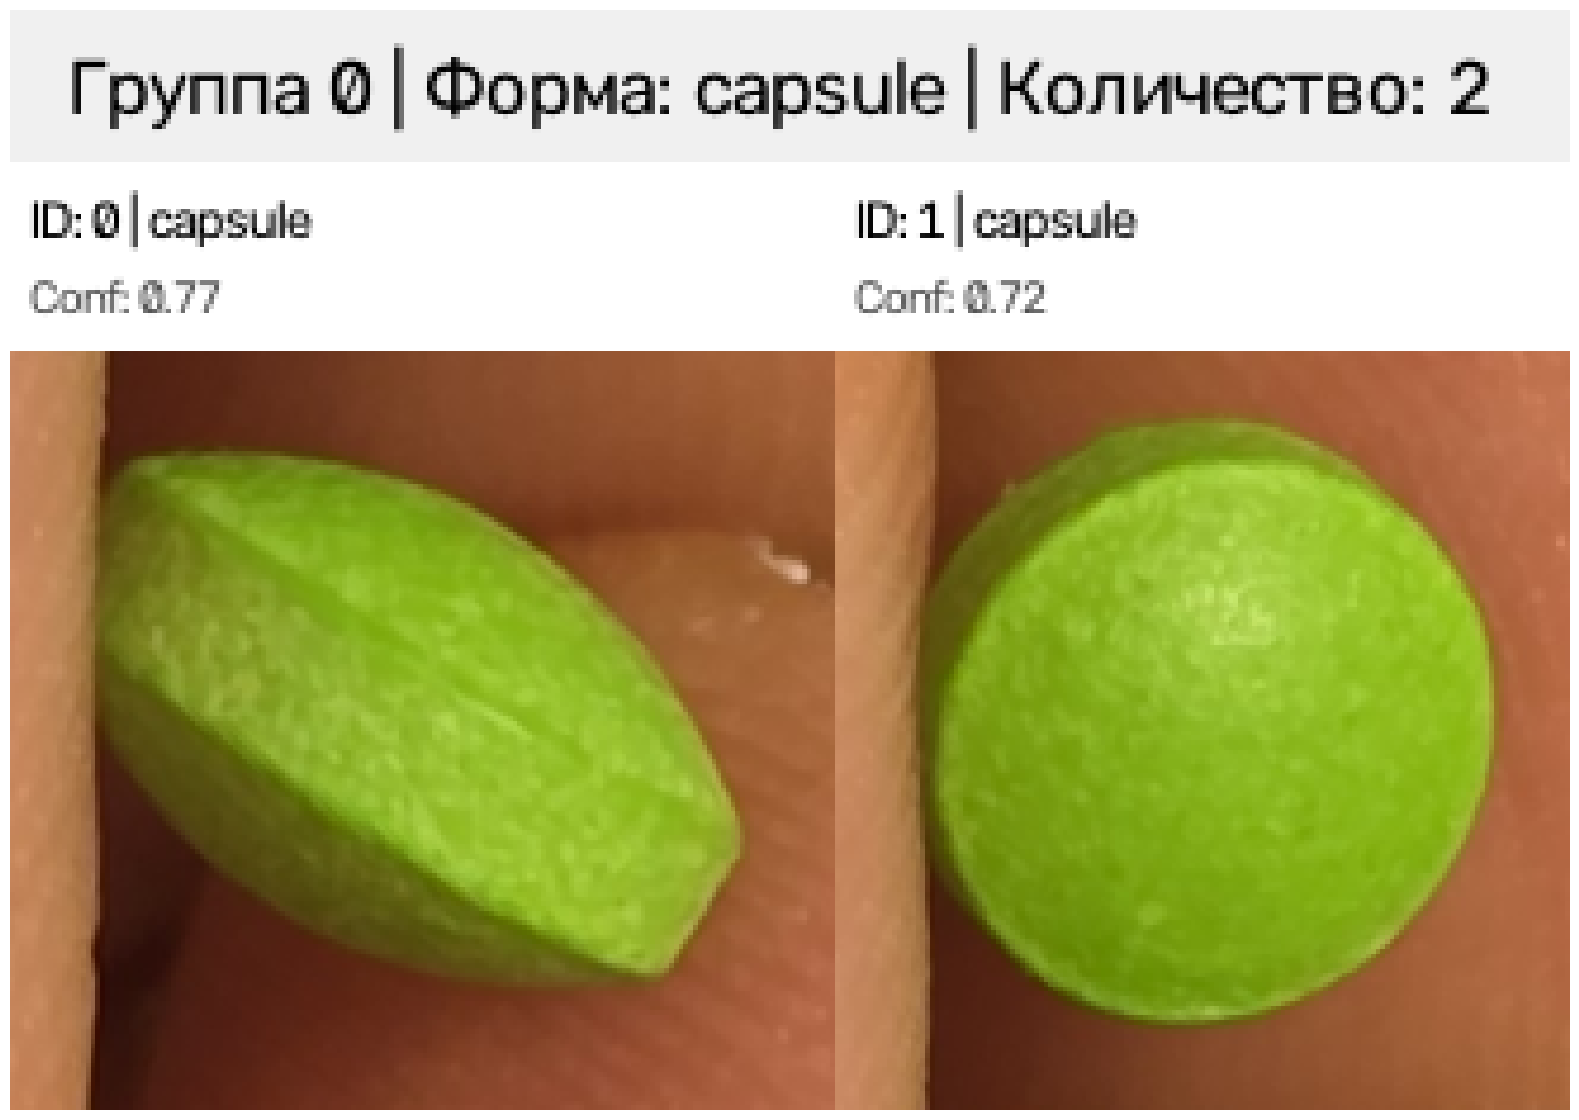

In [32]:
def visualize_pipeline_result(
    img_bgr: np.ndarray, crops_data: list[dict], report: dict
):
  if not crops_data or not report.get("drug_groups"):
    print("Нет обнаруженных объектов для отображения.")
    return

  target_h = 160  # Высота кропов
  header_h = 40  # Высота подписи над кропом
  title_h = 32  # Высота плашки группы

  cluster_rows = []

  for grp in report["drug_groups"]:
    gid = grp["group_id"]
    group_items = [c for c in crops_data if c["cluster_id"] == gid]
    group_title = f"Группа {gid} | Форма: {grp['dominant_form']} | Количество: {grp['count']}"

    tiles = []
    for item in group_items:
      crop_rgb = cv2.cvtColor(item["crop_bgr"], cv2.COLOR_BGR2RGB)

      # Пропорциональный ресайз к общей высоте
      h, w = crop_rgb.shape[:2]
      new_w = max(1, int(w * (target_h / h)))
      resized = cv2.resize(
          crop_rgb, (new_w, target_h), interpolation=cv2.INTER_AREA
      )

      # Формируем плитку с шапкой под текст
      tile = np.full((target_h + header_h, new_w, 3), 255, dtype=np.uint8)
      tile[header_h:, :] = resized

      text1 = f"ID: {item['crop_id']} | {item['class_name']}"
      text2 = f"Conf: {item['conf']:.2f}"
      cv2.putText(
          tile,
          text1,
          (4, 16),
          cv2.FONT_HERSHEY_SIMPLEX,
          0.38,
          (0, 0, 0),
          1,
          cv2.LINE_AA,
      )
      cv2.putText(
          tile,
          text2,
          (4, 32),
          cv2.FONT_HERSHEY_SIMPLEX,
          0.35,
          (80, 80, 80),
          1,
          cv2.LINE_AA,
      )
      tiles.append(tile)

    if not tiles:
      continue

    # Склеиваем кропы текущего кластера в горизонтальную полосу
    row_img = np.hstack(tiles)

    # Добавляем плашку с названием группы встык над строкой
    title_bar = np.full((title_h, row_img.shape[1], 3), 240, dtype=np.uint8)
    cv2.putText(
        title_bar,
        group_title,
        (12, 22),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.55,
        (0, 0, 0),
        1,
        cv2.LINE_AA,
    )

    full_row = np.vstack([title_bar, row_img])
    cluster_rows.append(full_row)

  if cluster_rows:
    # Дополняем строки белым цветом справа до максимальной ширины
    max_w = max(r.shape[1] for r in cluster_rows)
    padded_rows = []
    for r in cluster_rows:
      h, w, c = r.shape
      if w < max_w:
        pad = np.full((h, max_w - w, c), 255, dtype=np.uint8)
        r = np.hstack([r, pad])
      padded_rows.append(r)

    # Склеиваем все кластеры в единое вертикальное полотно
    canvas = np.vstack(padded_rows)

    total_h, total_w = canvas.shape[:2]
    fig_w = 16
    fig_h = max(3, int(fig_w * (total_h / total_w)))

    fig, ax = plt.subplots(figsize=(fig_w, fig_h))
    ax.imshow(canvas)
    ax.axis("off")
    plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
    plt.show()


# Визуализация
visualize_pipeline_result(img_bgr, crops, report)